In [1]:
import dipole
import minimizing
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate

In [2]:
lambda_qcd = 0.241 #GeV
conv_fmGeV = 5.068 # fm to GeV^-1
d = 0.54 * conv_fmGeV # GeV-1 
A = 197 # 197 for Au beam, 208 for Pb beam
conv_mbGeV2 = 2.56819

def RA(A):
    return (1.12 * A**(1/3) - 0.86*A**(-1/3))*conv_fmGeV # return in GeV^-1

def rhoA(z, bt, A): # Woods-Saxon distribution # GeV-1 
    ra = RA(A)
    n = 3.0/(4.0 * np.pi * RA(A)**3) * 1.0/(1.0 + (np.pi * d/RA(A))**2)
    B = (np.sqrt(bt**2 + z**2) - ra)/d
    rhoA = n / (1 + np.exp(B))
    return rhoA

# Woods-Saxon distribution T_A: rhoA integrated over z
def get_TA(bt, A): 
    TA = integrate.quad(rhoA, -999.0, 999.0, args = (bt, A))
    return TA[0]

def dipA(r, bt, A, Qs02, gamma, e_c, sigma0_2): # dipole nucleus
    sigma0_2 = sigma0_2 * 2.56819 # converted to 1/GeV2
    #n = woods_saxon_norm(A)
    #test = integrate.quad(lambda b: 2.0*np.pi*b*get_TA(b, A), 0, np.inf)
    #assert np.isclose(test[0], 1.0, atol=1e-3), "Thickness function not normalized to 1.0"
    TA = get_TA(bt, A) 
    B = A * TA * (sigma0_2)*((r**2)*(Qs02))**gamma
    C = 1/(r*lambda_qcd) + e_c * np.exp(1)
    N = 1 - np.exp(-B/4 * np.log(C))
    #print(TA)
    return N

In [3]:
#load initial condition parameters
params = np.loadtxt("../data/hm2013/mv_param.dat")
ic_qs, ic_ec, ic_c2, ic_sigma02 = params
print("Initial condition parameters: ", params)

Initial condition parameters:  [ 0.104  1.    14.5   18.81 ]


In [ ]:
bk_file = "../data/dipole/posterior/LOmvefit/0.dat"
#bk_file = '../data/nucleus/1/ic_197_0.dat'
#bk_file = '/home/caaucasu/sidis_fit/data/NLO/pd/MAP/0.dat'
#bk_file = "../data/hm2013/mv_bk.dat"
BKinterpolator = dipole.BKDipole(bk_file)
#init = [1.0, 0.8, 1.0, 1.0]
#init = [1.0, 0.8, 1.0, 0.8]
init =  [0.09, 1.6, 1.0, 1.0]
lbounds = [0.001, 0.1, 1/np.exp(1), 0.01]
ubounds = [10.0, 100.0, 100.0, 10.0]
grid_size = 10 #100
y_max = 8.0
y_array = np.linspace(0, y_max, grid_size)
r = np.logspace(-2, 2, 100)
Nyr = lambda yy,rr: BKinterpolator.ln_Nr(yy,rr) # Make interpolator to a callable function

fit_params_array = np.ones((len(y_array), 4))
i = 0
file_params = open("test.dat", "w")
for y in y_array:
    minimizer = minimizing.MyMinimizer(Nyr, y, r, init, lbounds = lbounds, ubounds = ubounds, lsmethod ='trf')
    out = minimizer.fit_ls()
    fit_params = out.x
    #print("fit_params", fit_params)
    fit_params_array[i, :] = fit_params
    # if y == 0 or y == 0.12:
    #     fit_params_array[i, :] = [ic_qs[0], 1.0, ic_ec[0], 1.0]
    #     fit_params_array[i, 0] = 197 * get_TA(0, A) * ic_sigma02[0] * conv_mbGeV2 * ic_qs[0]
    #fit_func = minimizer.parametrization(fit_params[0], fit_params[1], fit_params[2], fit_params[3])
    print('### y = ', np.round(y,3))
    print(fit_params_array[i, :] )
    init = fit_params
    i += 1

with file_params as f:
    f.write("#y, Qs2, gamma, ec, p \n")
    for l in range(grid_size):
        f.write("{: .6e} {: .6e} {: .6e} {: .6e} {: .6e} \n".format(y_array[l], fit_params_array[l, 0], fit_params_array[l, 1], fit_params_array[l, 2], fit_params_array[l, 3]))

Reading BK file: ../data/dipole/posterior/LOmvefit/0.dat


/home/caaucasu/sidis_fit/src/minimizing.py:28: RuntimeWarning: invalid value encountered in power
  exponent = (((r**2 * Qs2) ** gamma)/4 * np.log( (1/(r*lambda_qcd)) + np.exp(1)*ec ) )** p


### y =  0.0
[5.44260599e-02 9.99855844e-01 5.85528512e+01 1.00014139e+00]
### y =  0.081
[5.45631417e-02 8.25126842e-01 1.06743626e+02 1.20090629e+00]
### y =  0.162
[5.30803211e-02 6.06120800e-01 2.11057556e+02 1.62251938e+00]


(2, 20.0)

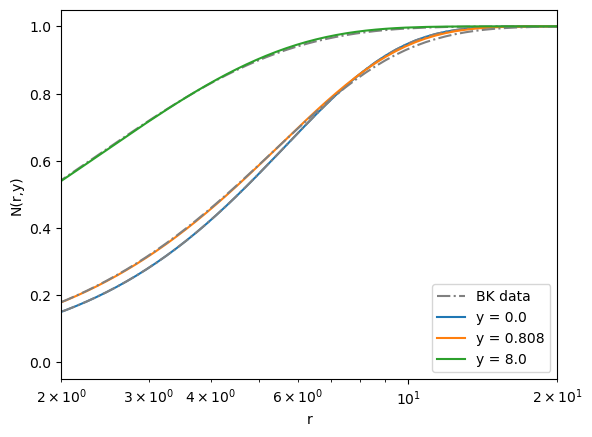

In [5]:
#i = 0
ind = range(0, len(y_array), len(y_array)//5)
ind = [0, 10, 99]
for i in ind:
    if i == 0:
        plt.plot(r, np.exp(Nyr(y,r)), '-.', color = 'gray', label = 'BK data')
    else:
        plt.plot(r, np.exp(Nyr(y,r)), '-.', color = 'gray')
    y = y_array[i]
    fit_params = fit_params_array[i, :]
    fit_func = minimizer.Ff(r, fit_params[0], fit_params[1], fit_params[2], fit_params[3])
    plt.plot(r, np.exp(fit_func), '-', label='y = '+str(np.round(y,3)))
    i += 1
plt.legend()
plt.xscale('log')
#plt.yscale('log')
plt.xlabel('r')
plt.ylabel('N(r,y)')
plt.xlim(2, 0.2e2)

## Get Fourier transform

In [21]:
interpolator = BKinterpolator.ReadBKDipole()[0]
from hankel import HankelTransform

def S(y,k):

    ht = HankelTransform(nu = 0, N = 1000, h = 0.001)

    def func_to_ht(r):
        f = interpolator(y, r) #minimizer.Ff(r, fit_params)
        f = np.nan_to_num(f, nan=1.0)
        return 1 - f

    sp_values = [ht.transform(func_to_ht, i, ret_err=False) for i in k]
    return np.array(sp_values)

def log_S2(k, fit_params):
    ht = HankelTransform(nu = 0, N = 1000, h = 0.001)

    def func_to_ht(r):
        f = minimizer.Ff(r, fit_params[0], fit_params[1], fit_params[2], fit_params[3])
        f = np.nan_to_num(f, nan=1.0)
        return 1 - f

    sp_values = [np.log10(ht.transform(func_to_ht, i, ret_err=False)) for i in k]
    return np.array(sp_values)

def S2(k, fit_params):
    ht = HankelTransform(nu = 0, N = 1000, h = 0.001)

    def func_to_ht(r):
        f = minimizer.Ff(r, fit_params[0], fit_params[1], fit_params[2], fit_params[3])
        f = np.nan_to_num(f, nan=1.0)
        return 1 - f

    sp_values = [ht.transform(func_to_ht, i, ret_err=False) for i in k]
    return np.array(sp_values)

Reading BK file: ../data/hm2013/mv_bk.dat


[0.10058879 1.03075855 0.95013835 0.96593278]
[-8.12409719e+05 -5.57832493e+05 -3.83027341e+05 -2.62997593e+05
 -1.80579318e+05 -1.23986921e+05 -8.51278434e+04 -5.84453392e+04
 -4.01238820e+04 -2.75435517e+04 -1.89053935e+04 -1.29741711e+04
 -8.90172989e+03 -6.10570967e+03 -4.18626297e+03 -2.86886607e+03
 -1.96504204e+03 -1.34537484e+03 -9.20955181e+02 -6.30617940e+02
 -4.32186425e+02 -2.96533412e+02 -2.03625642e+02 -1.39850258e+02
 -9.60358862e+01 -6.59443110e+01 -4.52807760e+01 -3.10913000e+01
 -2.13477766e+01 -1.46573833e+01 -1.00635683e+01 -6.90941458e+00
 -4.74379737e+00 -3.25692963e+00 -2.23609089e+00 -1.53521963e+00
 -1.05402867e+00 -7.23662027e-01 -4.96845082e-01 -3.41120873e-01
 -2.34205884e-01 -1.60801301e-01 -1.10403678e-01 -7.58018309e-02
 -5.20448713e-02 -3.57337153e-02 -2.45346742e-02 -1.68455113e-02
 -1.15661754e-02 -7.94139725e-03]


/tmp/ipykernel_177704/1387715200.py:11: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  plt.yscale('log')


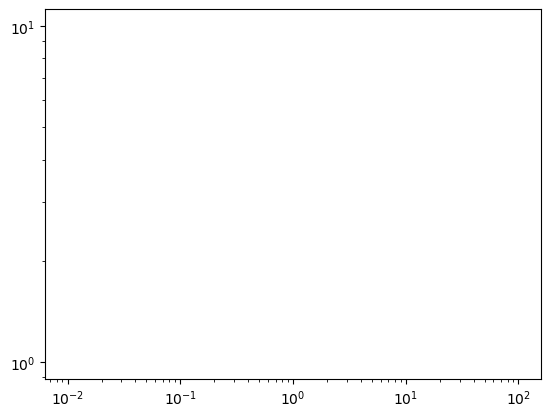

In [24]:
fit_params = fit_params_array[1] # last rapidity
print(fit_params)
k = np.logspace(-2, 2, 50)
Sk = S(0,k)
Sk2 = S2(k, fit_params)
print(Sk2)
#plt.plot(k, Sk, label='using Interpolator', color='red')
plt.plot(k, Sk2, '.', label = 'using fit', color='blue')
# plt.legend()
plt.xscale('log')
plt.yscale('log')

/tmp/ipykernel_173349/1442657786.py:24: RuntimeWarning: invalid value encountered in log10
  sp_values = [np.log10(ht.transform(func_to_ht, i, ret_err=False)) for i in k]


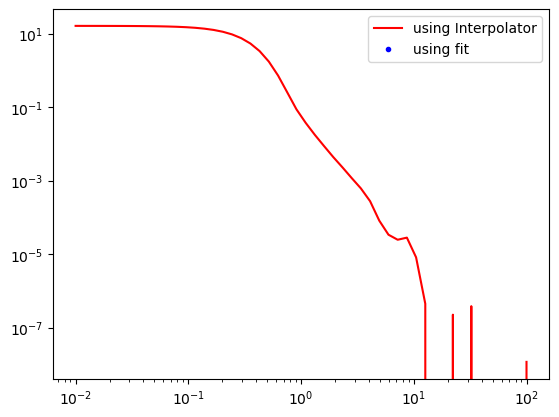

In [42]:
fit_params = fit_params_array[1]
k = np.logspace(-2, 2, 50)
Sk = S(0.12,k)
Sk2 = log_S2(k, fit_params)
plt.plot(k, Sk, label='using Interpolator', color='red')
plt.plot(k, 10**Sk2, '.', label = 'using fit', color='blue')
plt.legend()
plt.xscale('log')
plt.yscale('log')

[nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan]


/tmp/ipykernel_173349/1442657786.py:24: RuntimeWarning: invalid value encountered in log10
  sp_values = [np.log10(ht.transform(func_to_ht, i, ret_err=False)) for i in k]


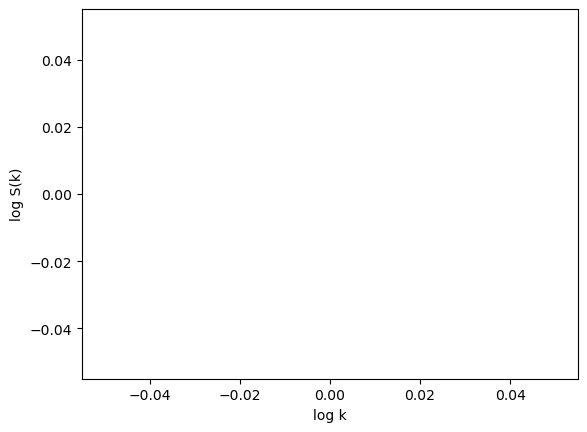

In [43]:
import pandas as pd
k_grid_size = 100#500
log_k_grid = np.linspace(-2, 2, k_grid_size)
log_Sk2 = log_S2(10**log_k_grid, fit_params)
plt.plot(log_k_grid, log_Sk2, '.',label='using fit at y=0.0', color='green')
plt.xlabel('log k')
plt.ylabel('log S(k)')
print(log_Sk2)

In [44]:
y_array_repeat = np.repeat(y_array, k_grid_size)
log_k_min = -2
log_k_max = 2
log_k_all = []
log_Sk2_all = []



for i in range(len(y_array)):
    fit_params = fit_params_array[i, :]
    log_k_grid = np.linspace(log_k_min, log_k_max, k_grid_size)
    log_Sk2 = log_S2(10**log_k_grid, fit_params)
    log_k_all.extend(log_k_grid)
    log_Sk2_all.extend(log_Sk2)

data = {'y': y_array_repeat, 'log10_k':log_k_all, 'log10_S(k)':log_Sk2_all}
df = pd.DataFrame(data)
print(np.shape(y_array_repeat))
print(np.shape(log_k_all))
print(np.shape(log_Sk2_all))

/tmp/ipykernel_173349/1442657786.py:24: RuntimeWarning: invalid value encountered in log10
  sp_values = [np.log10(ht.transform(func_to_ht, i, ret_err=False)) for i in k]


(10000,)
(10000,)
(10000,)


In [45]:
# csv_file = '../data/BKfit_Sk_data.csv'
# comments = ['## Generated from BK dipole with initial condition: MVe model, Q_s0^2 = 0.0544245 GeV^2, \gamma = 1, coefficient of E inside Log is 58.5321',
#                    '## Fitted to file {0}'.format(bk_file),
#                    '## Note definition of log S(k): log_S(k) = log10 S(k) = log10 [ \int r dr J0(k r) (1 - N(r)) ]',
#                    '## log10 k grid ranges from {0} to {1} with {2} points'.format(log_k_min, log_k_max, k_grid_size),
#                    '## y grid ranges from 0 to {0} with {1} points'.format(y_max, grid_size),]

# if save_files:
#     with open(csv_file, 'w') as f:
#         for comment in comments:
#             f.write(comment + '\n')
# df.to_csv(csv_file, index=False, sep = ' ', columns=['y', 'log10_k', 'log10_S(k)'], mode='a', float_format='%.6e') if save_files else None